# Cvičení 1: Barvy a segmentace podle barvy

Cílem cvičení je vyzkoušet si práci s barevnými prostory a tři jednoduché způsoby segmentace objektu podle barvy. Objektem bude tenisový míček na obrázku `data/tennis_ball2_small.jpg`.

1. Načtení obrázku
2. Segmentace prahováním v prostoru RGB
3. Segmentace prahováním v prostoru HSV
4. Segmentace zpětnou projekcí histogramu

Obecné pokyny:

- Můžete používat [OpenCV](https://docs.opencv.org/) nebo např. [scikit-image](https://scikit-image.org/).
- Výsledky vykreslujte pomocí [matplotlib](https://matplotlib.org/).
- Svůj kód pište na místa označená komentářem `# TODO: implement`.
- U každé segmentace (body 2 až 4) navíc spočítejte a vykreslete **bounding box** a **těžiště** míčku.
- Základem všech tří segmentací je prahování. Morfologické operace ani jiné následné úpravy masky nejsou vyžadovány, můžete je ale použít pro vylepšení výsledků.
- Každá sekce obsahuje vzorový výstup. Váš výsledek nemusí být na pixel stejný, ale měl by vypadat podobně.
- Za každým bodem je buňka s testy ze souboru `tests/test_colors.py`. Testy porovnávají vaši masku, bounding box a těžiště s ručně vytvořenou referenční segmentací míčku.
  - Masky a bounding boxy se porovnávají pomocí **Jaccardova indexu** (IoU, intersection over union)
    $$
    \mathrm{IoU}(A, B) = \frac{|A \cap B|}{|A \cup B|}
    $$
    kde $A$ je váš výsledek a $B$ reference. Hodnota 1 znamená dokonalou shodu, hodnota 0 žádný překryv.
  - U těžiště se měří vzdálenost od referenčního těžiště v pixelech.
  - Požadované hodnoty jsou uvedené u každé úlohy.

In [24]:
import sys

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

if ".." not in sys.path:
    sys.path.append("..")
from tests import test_colors

## 1. Načtení obrázku

- Načtěte obrázek `../data/tennis_ball2_small.jpg`.
- OpenCV načítá kanály v pořadí **BGR**, matplotlib očekává **RGB**. Převeďte obrázek do RGB a uložte jej do proměnné `rgb`.
- Vypište rozměry (`shape`) a datový typ (`dtype`) obrázku.
- Vykreslete vedle sebe barevný obrázek a jeho jednotlivé kanály R, G a B v odstínech šedi. Kanály se budou hodit při volbě prahů v dalším bodě.

Vzorový výstup:

<figure class="image">
  <img src="../figures/colors-expected_outputs_load.png" alt="Vzorový výstup" style="width: 100%"/>
</figure>

Rozměry: (499, 640, 3)
Datový typ: uint8


(np.float64(-0.5), np.float64(639.5), np.float64(498.5), np.float64(-0.5))

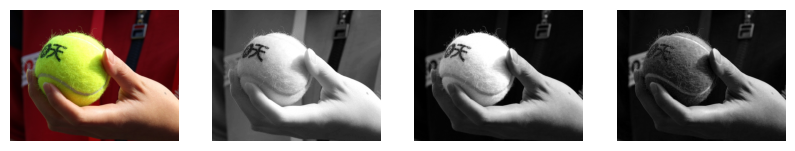

In [42]:
########################################
# TODO: implement

ball = cv.imread("../data/tennis_ball2_small.jpg")
rgb = cv.cvtColor(ball, cv.COLOR_BGR2RGB)
print("Rozměry:", rgb.shape)
print("Datový typ:", rgb.dtype)
plt.figure(figsize=(10, 5))
plt.subplot(1, 4, 1)
plt.imshow(rgb)
plt.axis("off")
plt.subplot(1, 4, 2)
plt.imshow(rgb[:, :, 0], cmap="gray")
plt.axis("off")
plt.subplot(1, 4, 3)
plt.imshow(rgb[:, :, 1], cmap="gray")
plt.axis("off")
plt.subplot(1, 4, 4)
plt.imshow(rgb[:, :, 2], cmap="gray")
plt.axis("off")

########################################

In [26]:
test_colors.TestLoadImage.eval(rgb=rgb)

test_channel_order (tests.PVITestCase.eval.<locals>._TestCaseClass.test_channel_order) ... ok
test_image (tests.PVITestCase.eval.<locals>._TestCaseClass.test_image) ... ok

----------------------------------------------------------------------
Ran 2 tests in 0.031s

OK


<unittest.runner.TextTestResult run=2 errors=0 failures=0>

## Pomocná funkce: bounding box a těžiště

Bounding box a těžiště budeme potřebovat ve všech třech segmentačních úlohách, proto si je připravíme předem jako funkci.

- `bbox_and_centroid(mask)`
  - Vstupem je binární maska (`uint8`, hodnoty 0 a 255).
  - Vrátí bounding box všech nenulových pixelů jako čtveřici `(x, y, w, h)` a těžiště jako dvojici `(cx, cy)` v pixelech.
  - Těžiště spočítejte z obrazových momentů: $c_x = m_{10} / m_{00}$, $c_y = m_{01} / m_{00}$.

In [27]:
def bbox_and_centroid(mask: np.ndarray) -> tuple[tuple[int, int, int, int], tuple[float, float]]:
    """
    Compute the bounding box and the centroid of a binary mask.

    Args:
        mask: Binary mask of dtype uint8 with values 0 and 255.
    Returns:
        Bounding box (x, y, w, h) and centroid (cx, cy) in pixels.
    """
    ########################################
    # TODO: implement
    
    x, y, w, h = cv.boundingRect(mask)
    moments = cv.moments(mask)
    cx = moments["m10"] / moments["m00"]
    cy = moments["m01"] / moments["m00"]

    return (x, y, w, h), (cx, cy)

    ########################################

In [28]:
test_colors.TestBboxAndCentroid.eval(bbox_and_centroid_fn=bbox_and_centroid)

test_bbox (tests.PVITestCase.eval.<locals>._TestCaseClass.test_bbox) ... ok
test_centroid (tests.PVITestCase.eval.<locals>._TestCaseClass.test_centroid) ... ok

----------------------------------------------------------------------
Ran 2 tests in 0.013s

OK


<unittest.runner.TextTestResult run=2 errors=0 failures=0>

## 2. Segmentace prahováním v prostoru RGB

- Stejná barva má na osvětlené a zastíněné straně míčku velmi odlišné hodnoty R, G a B, takže prahování původních kanálů nefunguje dobře. Vliv jasu lze potlačit přechodem na **relativní zastoupení** jednotlivých složek
  $$
  r = \frac{R}{R + G + B}, \qquad g = \frac{G}{R + G + B}, \qquad b = \frac{B}{R + G + B}
  $$
  - Před dělením převeďte obrázek na desetinná čísla a ošetřete dělení nulou u černých pixelů.
- Zvolte prahy relativních složek tak, aby maska pokrývala míček a co nejméně pozadí.
  - Míček je žlutozelený, má tedy vysoký podíl zelené složky. Červené pozadí i kůže ruky mají podíl zelené výrazně nižší.
- **Nápověda:** samotné relativní složky nestačí. U tmavých pixelů je součet $R + G + B$ malý, relativní složky jsou proto zašuměné a v tmavém pozadí vznikají falešné detekce. Prahujte proto zároveň i **jas**, např. součet $R + G + B$, a tmavé pixely z masky vyřaďte.
- Vytvořte binární masku typu `uint8` s hodnotami 0 a 255 a uložte ji do proměnné `mask_rgb`.
- Spočítejte bounding box a těžiště masky (`bbox_rgb`, `centroid_rgb`) a vypište je.
- Vykreslete trojici obrázků: původní RGB, binární masku a RGB s vyznačeným bounding boxem a těžištěm pomocí `ax.plot`.
- Vyzkoušejte si prahování bez podmínky na jas. Co se stane s bounding boxem a co s těžištěm? Proč je bounding box na osamocené falešné pixely mnohem citlivější?
- Požadavky testů: IoU masky alespoň **0,75**, IoU bounding boxu alespoň **0,85**, těžiště nejvýše **20 px** od reference.

Vzorový výstup:

<figure class="image">
  <img src="../figures/colors-expected_outputs_rgb.png" alt="Vzorový výstup" style="width: 100%"/>
</figure>

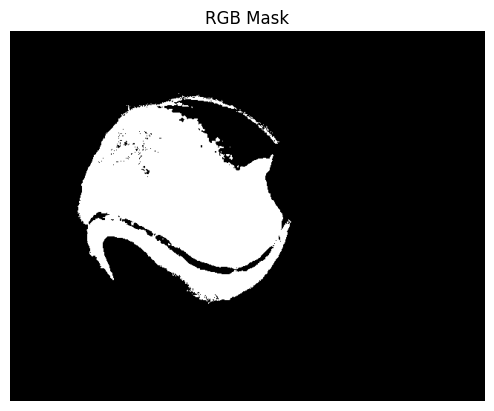

In [39]:
########################################
# TODO: implement


rgb_float = rgb.astype(np.float32)
rgb_sum = np.sum(rgb_float, axis=2)
sum_rgb = np.where(rgb_sum == 0, 1, rgb_sum)

r = rgb_float[:, :, 0] / rgb_sum
g = rgb_float[:, :, 1] / rgb_sum
b = rgb_float[:, :, 2] / rgb_sum

mask_rgb = np.zeros_like(r, dtype=np.uint8)
g_mask = g > 0.4
r_mask = r < 0.6
b_mask = b < 0.6
brightness_mask = rgb_sum > 50

mask_rgb[g_mask & r_mask & b_mask & brightness_mask] = 255
bbox_rgb, centroid_rgb = bbox_and_centroid(mask_rgb)

plt.imshow(mask_rgb, cmap="gray")
plt.title("RGB Mask")
plt.axis("off")
plt.show()

########################################

In [30]:
test_colors.TestSegmentationRGB.eval(mask=mask_rgb, bbox=bbox_rgb, centroid=centroid_rgb)

test_bbox (tests.PVITestCase.eval.<locals>._TestCaseClass.test_bbox) ... ok
test_centroid (tests.PVITestCase.eval.<locals>._TestCaseClass.test_centroid) ... ok
test_mask (tests.PVITestCase.eval.<locals>._TestCaseClass.test_mask) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.019s

OK


Bounding box IoU: 0.952
Centroid distance: 11.3 px
Mask IoU: 0.811


<unittest.runner.TextTestResult run=3 errors=0 failures=0>

## 3. Segmentace prahováním v prostoru HSV

- Převeďte obrázek do prostoru HSV. Výsledek uložte do proměnné `hsv`.
  - Pozor: pro 8bitové obrázky má v OpenCV kanál H rozsah **0 až 179** (úhel ve stupních dělený dvěma), kanály S a V mají rozsah 0 až 255.
- Barvu míčku vymezte pomocí kanálu **H** (odstín). Zvolte dolní a horní mez odstínu tak, aby odpovídaly žlutozelené barvě míčku.
  - Pomůže histogram kanálu H nebo jeho vykreslení jako obrázku.
- **Nápověda:** samotný odstín nestačí. U tmavých pixelů je odstín nespolehlivý a v tmavém pozadí vznikají falešné detekce. Prahujte proto zároveň i **jas** (kanál V) a tmavé pixely z masky vyřaďte. Kanál S nepoužívejte.
- Vytvořte binární masku typu `uint8` s hodnotami 0 a 255 a uložte ji do proměnné `mask_hsv`.
- Spočítejte bounding box a těžiště masky (`bbox_hsv`, `centroid_hsv`) a vypište je.
- Vykreslete trojici obrázků: původní RGB, binární masku a RGB s vyznačeným bounding boxem a těžištěm pomocí `ax.plot`.
- Požadavky testů: IoU masky alespoň **0,75**, IoU bounding boxu alespoň **0,75**, těžiště nejvýše **20 px** od reference.
- Porovnejte výsledek s prahováním v RGB. Který prostor se pro volbu prahů hodí lépe a proč? Která část míčku v masce chybí?

Vzorový výstup:

<figure class="image">
  <img src="../figures/colors-expected_outputs_hsv.png" alt="Vzorový výstup" style="width: 100%"/>
</figure>

(np.float64(-0.5), np.float64(639.5), np.float64(498.5), np.float64(-0.5))

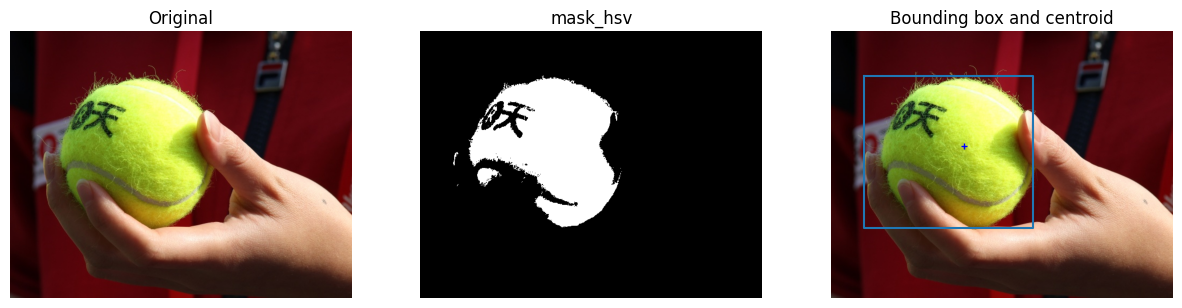

In [45]:
########################################
# TODO: implement

hsv = cv.cvtColor(rgb, cv.COLOR_RGB2HSV)
# plt.imshow(hsv)
mask_hsv = np.zeros_like(hsv[:, :, 0], dtype=np.uint8)
h = hsv[:, :, 0]
v = hsv[:, :, 2]
h_mask = (h > 20) & (h < 70)
v_mask = v > 120
mask_hsv[h_mask & v_mask] = 255

bbox_hsv, centroid_hsv = bbox_and_centroid(mask_hsv)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask_hsv, cmap="gray")
plt.title("mask_hsv")
plt.axis("off")

ax = plt.subplot(1, 3, 3)
ax.imshow(rgb)
x, y, w, h = bbox_hsv
ax.plot([x, x + w, x + w, x, x], [y, y, y + h, y + h, y])
ax.plot(centroid_hsv[0], centroid_hsv[1], "b+", markersize=5)
ax.set_title("Bounding box and centroid")
plt.axis("off")


########################################

In [46]:
test_colors.TestSegmentationHSV.eval(mask=mask_hsv, bbox=bbox_hsv, centroid=centroid_hsv)

test_bbox (tests.PVITestCase.eval.<locals>._TestCaseClass.test_bbox) ... ok
test_centroid (tests.PVITestCase.eval.<locals>._TestCaseClass.test_centroid) ... ok
test_mask (tests.PVITestCase.eval.<locals>._TestCaseClass.test_mask) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.019s

OK


Bounding box IoU: 0.857
Centroid distance: 10.7 px
Mask IoU: 0.804


<unittest.runner.TextTestResult run=3 errors=0 failures=0>

## 4. Segmentace zpětnou projekcí histogramu

Místo ručního ladění prahů si barvu míčku „naučíme“ z ukázky: z vybrané části míčku spočítáme referenční histogram a pro každý pixel obrázku pak zjistíme, jak často se jeho barva v ukázce vyskytovala.

- Ručně zadejte souřadnice obdélníku `(x, y, w, h)`, který leží celý uvnitř míčku. Obdélník by měl obsahovat co nejvíce odstínů míčku, ale ne šev ani nápis.
- Z výřezu spočítejte jednorozměrný histogram **pouze kanálu H** (odstín) v prostoru HSV.
  - Kanál H má v OpenCV rozsah 0 až 179, použijte tedy 180 binů.
- Histogram normalizujte do rozsahu 0 až 255 a uložte do proměnné `hist`.
- Spočítejte zpětnou projekci histogramu na celý obrázek a uložte ji do proměnné `backproj`.
- Zpětnou projekci naprahujte na binární masku typu `uint8` s hodnotami 0 a 255 a uložte ji do proměnné `mask_bp`.
- **Nápověda:** zpětná projekce odstínu trpí u tmavých pixelů stejně jako prahování odstínu v bodě 3. I zde proto z masky vyřaďte pixely s nízkým **jasem** (kanál V).
- Spočítejte bounding box a těžiště masky (`bbox_bp`, `centroid_bp`) a vypište je.
- Vykreslete čtveřici obrázků: původní RGB s vyznačeným referenčním obdélníkem, zpětná projekce, binární maska, RGB s bounding boxem a těžištěm.
- Histogram malého výřezu nepokryje všechny odstíny míčku, proto jsou požadavky testů nižší: IoU masky alespoň **0,7**, IoU bounding boxu alespoň **0,7**, těžiště nejvýše **30 px** od reference.
- Která část míčku ve výsledku chybí a proč? Čím by šlo metodu vylepšit?

Vzorový výstup:

<figure class="image">
  <img src="../figures/colors-expected_outputs_backprojection.png" alt="Vzorový výstup" style="width: 100%"/>
</figure>

Bounding box: (65, 87, 299, 257)
Centroid: (249.32411134280588, 209.80064012414527)


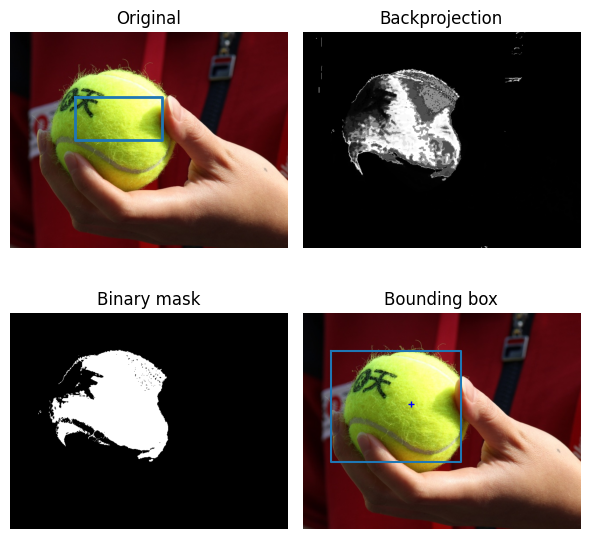

In [53]:

########################################
# TODO: implement

x, y, w, h = 150, 150, 200, 100
plt.figure(figsize=(6, 6))
plt.subplot(2, 2, 1)
plt.imshow(rgb)
plt.title("Original")
plt.plot([x, x + w, x + w, x, x], [y, y, y + h, y + h, y], linewidth=2)
plt.axis("off")

hsv_area = hsv[y:y+h, x:x+w]
h_area = hsv_area[:, :, 0]
hist = cv.calcHist([h_area], [0], None, [180], [0, 180])
# print(hist)
# hist = cv.blur(hist, (6, 1))
hist = cv.normalize(hist, hist, 0, 255, cv.NORM_MINMAX)

backproj = cv.calcBackProject([hsv[:, :, 0]], [0], hist, [0, 180], scale=1)
mask_bp = np.zeros_like(backproj, dtype=np.uint8)
h_mask = backproj > 30
v_mask = hsv[:, :, 2] > 100
mask_bp[h_mask & v_mask] = 255
bbox_bp, centroid_bp = bbox_and_centroid(mask_bp)
print("Bounding box:", bbox_bp)
print("Centroid:", centroid_bp)

# plt.figure(figsize=(6, 6))
plt.subplot(2, 2, 2)
plt.imshow(backproj, cmap="gray")
plt.title("Backprojection")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(mask_bp, cmap="gray")
plt.title("Binary mask")
plt.axis("off")

ax = plt.subplot(2, 2, 4)
ax.imshow(rgb)
bx, by, bw, bh = bbox_bp
ax.plot([bx, bx + bw, bx + bw, bx, bx], [by, by, by + bh, by + bh, by])
ax.plot(centroid_bp[0], centroid_bp[1], "b+", markersize=5)
ax.set_title("Bounding box")
plt.axis("off")

plt.tight_layout()
plt.show()

########################################

In [34]:
test_colors.TestHueHistogram.eval(hist=hist)

test_format (tests.PVITestCase.eval.<locals>._TestCaseClass.test_format) ... ok
test_normalization (tests.PVITestCase.eval.<locals>._TestCaseClass.test_normalization) ... ok
test_peak (tests.PVITestCase.eval.<locals>._TestCaseClass.test_peak) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.008s

OK


Histogram peak: H=35


<unittest.runner.TextTestResult run=3 errors=0 failures=0>

In [35]:
test_colors.TestBackprojection.eval(backproj=backproj)

test_backprojection (tests.PVITestCase.eval.<locals>._TestCaseClass.test_backprojection) ... ok

----------------------------------------------------------------------
Ran 1 test in 0.006s

OK


Mean backprojection: 121.0 on the ball, 0.7 on the background


<unittest.runner.TextTestResult run=1 errors=0 failures=0>

In [36]:
test_colors.TestSegmentationBackprojection.eval(mask=mask_bp, bbox=bbox_bp, centroid=centroid_bp)

test_bbox (tests.PVITestCase.eval.<locals>._TestCaseClass.test_bbox) ... ok
test_centroid (tests.PVITestCase.eval.<locals>._TestCaseClass.test_centroid) ... ok
test_mask (tests.PVITestCase.eval.<locals>._TestCaseClass.test_mask) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.018s

OK


Bounding box IoU: 0.771
Centroid distance: 14.7 px
Mask IoU: 0.723


<unittest.runner.TextTestResult run=3 errors=0 failures=0>